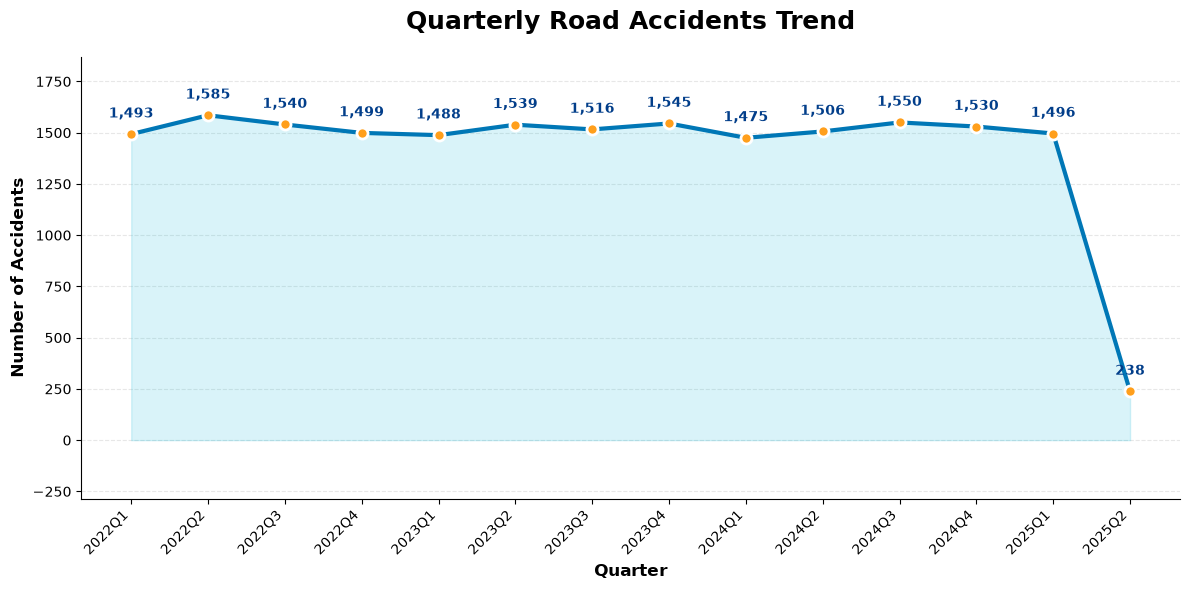

In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Convert date column into datetime format
if 'df' not in globals():
    csv_path = Path("indian_roads_dataset.csv")

    # Search the notebook's working directory and its subfolders if needed
    if not csv_path.exists():
        matches = list(Path.cwd().rglob("indian_roads_dataset.csv"))
        if matches:
            csv_path = matches[0]
        else:
            raise FileNotFoundError(
                f"indian_roads_dataset.csv was not found under {Path.cwd()}. "
                "Place the file there or update csv_path to its location."
            )

    df = pd.read_csv(csv_path)

df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Remove rows with invalid dates
df = df.dropna(subset=['date']).copy()

# Group accidents by quarter
df['Quarter'] = df['date'].dt.to_period('Q')
trend = df.groupby('Quarter').size()

# Create an attractive graph
fig, ax = plt.subplots(figsize=(12, 6))

# Plot line and markers
ax.plot(
    range(len(trend)),
    trend.values,
    color='#0077B6',
    linewidth=3,
    marker='o',
    markersize=8,
    markerfacecolor='#FF9F1C',
    markeredgecolor='white',
    markeredgewidth=2
)

# Add a light shaded area
ax.fill_between(
    range(len(trend)),
    trend.values,
    color='#00B4D8',
    alpha=0.15
)

# Display accident counts above each point
for i, value in enumerate(trend.values):
    ax.annotate(
        f'{value:,}',
        (i, value),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#023E8A'
    )

# Title and labels
ax.set_title(
    'Quarterly Road Accidents Trend',
    fontsize=18,
    fontweight='bold',
    pad=20
)
ax.set_xlabel('Quarter', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Accidents', fontsize=12, fontweight='bold')

# Format x-axis labels
ax.set_xticks(range(len(trend)))
ax.set_xticklabels(
    [str(q) for q in trend.index],
    rotation=45,
    ha='right'
)

# Improve graph appearance
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.margins(y=0.18)

plt.tight_layout()
plt.show()